In [2]:
import os
BASE_PATH = "./final_dataset_A"
def inspect_dataset(base_path):
    for split in ["train", "val", "cross_gen_test"]:
        print(f"\n--- {split.upper()} ---")

        split_path = os.path.join(base_path, split)

        if not os.path.exists(split_path):
            print("❌ Missing:", split_path)
            continue

        for cls in ["real", "fake"]:
            cls_path = os.path.join(split_path, cls)

            if not os.path.exists(cls_path):
                print(f"❌ Missing class folder: {cls}")
                continue

            count = len(os.listdir(cls_path))
            print(f"{cls}: {count} images")

inspect_dataset(BASE_PATH)


--- TRAIN ---
real: 15000 images
fake: 15000 images

--- VAL ---
real: 2500 images
fake: 2500 images

--- CROSS_GEN_TEST ---
real: 2500 images
fake: 2500 images


In [3]:
from PIL import Image

def remove_corrupt_images(base_path):
    removed = 0

    for split in ["train", "val", "cross_gen_test"]:
        for cls in ["real", "fake"]:
            folder = os.path.join(base_path, split, cls)

            for file in os.listdir(folder):
                path = os.path.join(folder, file)

                try:
                    img = Image.open(path)
                    img.verify()
                except:
                    os.remove(path)
                    removed += 1

    print(f"Removed {removed} corrupted images")

remove_corrupt_images(BASE_PATH)

Removed 0 corrupted images


In [4]:
def check_image_shapes(base_path):
    from PIL import Image

    for split in ["train", "val"]:
        for cls in ["real", "fake"]:
            folder = os.path.join(base_path, split, cls)

            for file in os.listdir(folder)[:20]:  # sample check
                path = os.path.join(folder, file)

                img = Image.open(path)

                print(path, img.mode, img.size)

check_image_shapes(BASE_PATH)

./final_dataset_A/train/real/TR_010450.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_011996.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_000643.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_009101.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_006232.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_012247.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_002054.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_014636.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_004425.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_013159.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_004343.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_014150.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_002732.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_012521.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_011028.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_009667.jpg RGB (256, 256)
./final_dataset_A/train/real/TR_006554.jpg RGB (256, 256)
./final_datase

In [5]:
def class_balance(base_path):
    for split in ["train", "val"]:
        print(f"\n{split.upper()}")

        real = len(os.listdir(os.path.join(base_path, split, "real")))
        fake = len(os.listdir(os.path.join(base_path, split, "fake")))

        print("real:", real)
        print("fake:", fake)
        print("ratio:", real / (fake + 1))

class_balance(BASE_PATH)


TRAIN
real: 15000
fake: 15000
ratio: 0.9999333377774815

VAL
real: 2500
fake: 2500
ratio: 0.9996001599360256


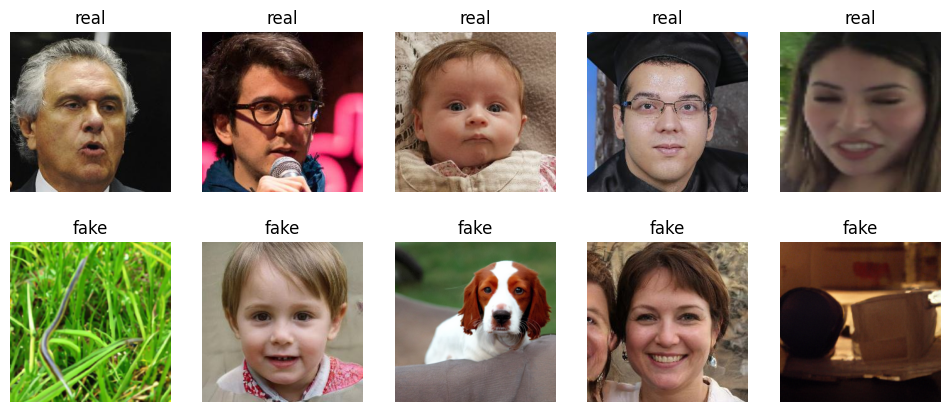

In [6]:
import matplotlib.pyplot as plt
import random

def show_samples(base_path):
    fig, axes = plt.subplots(2, 5, figsize=(12,5))

    for i, cls in enumerate(["real", "fake"]):
        folder = os.path.join(base_path, "train", cls)
        imgs = random.sample(os.listdir(folder), 5)

        for j, img_name in enumerate(imgs):
            img = Image.open(os.path.join(folder, img_name))

            axes[i][j].imshow(img)
            axes[i][j].set_title(cls)
            axes[i][j].axis("off")

    plt.show()

show_samples(BASE_PATH)

In [5]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

train_ds = datasets.ImageFolder(
    os.path.join(BASE_PATH, "train"),
    transform=transform
)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

In [8]:
for imgs, labels in train_loader:
    print("Images shape:", imgs.shape)
    print("Labels:", labels)
    break

Images shape: torch.Size([8, 3, 224, 224])
Labels: tensor([1, 1, 1, 1, 0, 0, 0, 0])


In [11]:
!pip install timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 3.8 MB/s  0:00:00 eta 0:00:01


In [28]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Using:", device)

Using: mps


In [4]:
import torch.nn as nn
import timm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from pathlib import Path
import numpy as np
import time

In [41]:
DATASET_ROOT = Path("./final_dataset_A")   # your dataset folder
CKPT_DIR     = Path.home() / "diffusion_detector_checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("Checkpoints will be saved to:", CKPT_DIR)

Checkpoints will be saved to: /Users/anupdangi/diffusion_detector_checkpoints


In [3]:
import torch
import torch.nn as nn
import timm

class HybridModel(nn.Module):
    def __init__(self, freeze_backbone=True):
        super().__init__()

        # ── Branch 1: ViT ──────────────────────────────────
        self.vit = timm.create_model(
            "vit_small_patch16_224",
            pretrained=True,
            num_classes=0       # outputs 384-d features
        )
        if freeze_backbone:
            for p in self.vit.parameters():
                p.requires_grad = False

        self.vit_fc = nn.Linear(384, 256)

        # ── Branch 2: NPR CNN ───────────────────────────────
        self.npr_cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.npr_fc = nn.Linear(128, 256)

        # ── Attention Fusion ────────────────────────────────
        self.attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

        # ── Final Classifier ────────────────────────────────
        self.head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # ── ViT features ──
        vit_feat = self.vit(x)               # (B, 384)
        vit_feat = self.vit_fc(vit_feat)     # (B, 256)

        # ── NPR: pixel difference map → CNN ──
        npr = torch.abs(x[:, :, :-2, :-2] - x[:, :, 2:, 2:])
        npr_feat = self.npr_cnn(npr)                              # (B, 128, 1, 1)
        npr_feat = self.npr_fc(npr_feat.view(npr_feat.size(0), -1))  # (B, 256)

        # ── Stack both branches ──
        feats = torch.stack([vit_feat, npr_feat], dim=1)         # (B, 2, 256)

        # ── Attention weights ──
        weights = self.attn(feats)                               # (B, 2, 1)
        weights = torch.softmax(weights.squeeze(-1), dim=1)      # (B, 2)

        # ── Weighted fusion ──
        fused = (feats * weights.unsqueeze(-1)).sum(dim=1)       # (B, 256)

        # ── Output logit ──
        return self.head(fused).squeeze(1)                       # (B,)

    def unfreeze_last_blocks(self, n=2):
        for block in self.vit.blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True
        print(f"✅ Unfrozen last {n} ViT blocks")


# ── Instantiate ─────────────────────────────────────────────
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

model     = HybridModel(freeze_backbone=True).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=5, eta_min=1e-6
)

print("✅ Model ready on:", DEVICE)
print(f"   Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/Users/anupdangi/Desktop/AnupAI/Research/DS_ML_DL_NLP_BOOTCAMP/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Model ready on: mps
   Trainable params: 291,074


In [38]:
def evaluate(loader, name):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            with torch.autocast("mps"):
                logits = model(imgs)
            probs = torch.sigmoid(logits).float().cpu().numpy()
            all_probs.extend(probs)
            all_labels.extend(labels.numpy())
    auc = roc_auc_score(all_labels, all_probs)
    acc = ((np.array(all_probs) > 0.5).astype(int) == np.array(all_labels)).mean()
    print(f"  {name:20s}  AUC={auc:.4f}  Acc={acc:.4f}")
    return auc

In [39]:
PHASE1_EPOCHS = 5
best_auc = 0.0

for epoch in range(1, PHASE1_EPOCHS + 1):
    model.train()
    total_loss = 0.0
    t0 = time.time()

    for imgs, labels in train_loader:
        imgs   = imgs.to(DEVICE)
        labels = labels.float().to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("mps"):
            logits = model(imgs)
            loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    scheduler.step()
    va_auc = evaluate(val_loader, "Val")
    marker  = " ★" if va_auc > best_auc else ""
    print(f"Epoch {epoch}  Loss={total_loss/len(train_loader):.4f}  AUC={va_auc:.4f}{marker}")

    if va_auc > best_auc:
        best_auc = va_auc
        torch.save(model.state_dict(), CKPT_DIR / "vit_baseline_best.pt")

  Val                   AUC=0.9670  Acc=0.9056
Epoch 1  Loss=0.4121  AUC=0.9670 ★
  Val                   AUC=0.9728  Acc=0.8848
Epoch 2  Loss=0.3246  AUC=0.9728 ★
  Val                   AUC=0.9771  Acc=0.9210
Epoch 3  Loss=0.2963  AUC=0.9771 ★
  Val                   AUC=0.9784  Acc=0.9210
Epoch 4  Loss=0.2804  AUC=0.9784 ★
  Val                   AUC=0.9787  Acc=0.9228
Epoch 5  Loss=0.2701  AUC=0.9787 ★


In [42]:
print("\n── Phase 2: Unfreeze last 2 blocks ──")
model.unfreeze_last_blocks(n=2)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-5, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=5, eta_min=1e-7
)

print(f"{'Epoch':>5}  {'Loss':>8}  {'Val AUC':>8}  {'Time':>6}")
print("─" * 38)

for epoch in range(1, 6):
    model.train()
    total_loss = 0.0
    t0 = time.time()

    for batch_idx, (imgs, labels) in enumerate(train_loader):  # ← enumerate added
        imgs   = imgs.to(DEVICE)
        labels = labels.float().to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("mps"):
            logits = model(imgs)
            loss   = criterion(logits, labels)

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        # ── Progress every 10 batches ──────────────────────
        if batch_idx % 10 == 0:
            print(f"  Epoch {epoch} | Batch {batch_idx}/{len(train_loader)} "
                  f"| Loss: {loss.item():.4f}", flush=True)  # flush=True forces immediate print

    scheduler.step()
    va_auc = evaluate(val_loader, "Val")
    elapsed = time.time() - t0
    marker  = " ★" if va_auc > best_auc else ""

    print(f"{epoch:>5}  {total_loss/len(train_loader):>8.4f}  "
          f"{va_auc:>8.4f}  {elapsed:>5.0f}s{marker}")

    if va_auc > best_auc:
        best_auc = va_auc
        torch.save(model.state_dict(), CKPT_DIR / "vit_baseline_best.pt")


── Phase 2: Unfreeze last 2 blocks ──
✅ Unfrozen last 2 ViT blocks
Epoch      Loss   Val AUC    Time
──────────────────────────────────────
  Epoch 1 | Batch 0/469 | Loss: 0.1201
  Epoch 1 | Batch 10/469 | Loss: 0.3313
  Epoch 1 | Batch 20/469 | Loss: 0.2482
  Epoch 1 | Batch 30/469 | Loss: 0.1817
  Epoch 1 | Batch 40/469 | Loss: 0.2467
  Epoch 1 | Batch 50/469 | Loss: 0.3300
  Epoch 1 | Batch 60/469 | Loss: 0.3901
  Epoch 1 | Batch 70/469 | Loss: 0.3108
  Epoch 1 | Batch 80/469 | Loss: 0.3681
  Epoch 1 | Batch 90/469 | Loss: 0.2908
  Epoch 1 | Batch 100/469 | Loss: 0.3078
  Epoch 1 | Batch 110/469 | Loss: 0.2574
  Epoch 1 | Batch 120/469 | Loss: 0.2093
  Epoch 1 | Batch 130/469 | Loss: 0.2314
  Epoch 1 | Batch 140/469 | Loss: 0.2454
  Epoch 1 | Batch 150/469 | Loss: 0.3284
  Epoch 1 | Batch 160/469 | Loss: 0.3251
  Epoch 1 | Batch 170/469 | Loss: 0.2818
  Epoch 1 | Batch 180/469 | Loss: 0.2462
  Epoch 1 | Batch 190/469 | Loss: 0.3483
  Epoch 1 | Batch 200/469 | Loss: 0.2307
  Epoch 1

In [43]:
torch.save(model.state_dict(), "./vit_baseline_final.pt")

In [ ]:
torch.load("./backend/models/model1/vit_finetuned.pt")

Using dataset from: ../dataset/complete_merged_dataset
Loading model from: /Users/anupdangi/Desktop/AnupAI/projects/Internship_project/deepfake_image_detection/backend/models/model1/vit_finetuned.pt
✅ Model checkpoint loaded
✅ Validation set: 7069 images
✅ Test set: 7071 images

CONFUSION MATRICES

📊 VALIDATION SET Confusion Matrix:
[[2149 1545]
 [  79 3296]]
   Format: [[TN, FP], [FN, TP]]
   Accuracy: 0.7703
   F1 Score: 0.8023

📊 TEST SET Confusion Matrix:
[[2172 1523]
 [  76 3300]]
   Format: [[TN, FP], [FN, TP]]
   Accuracy: 0.7739
   F1 Score: 0.8050


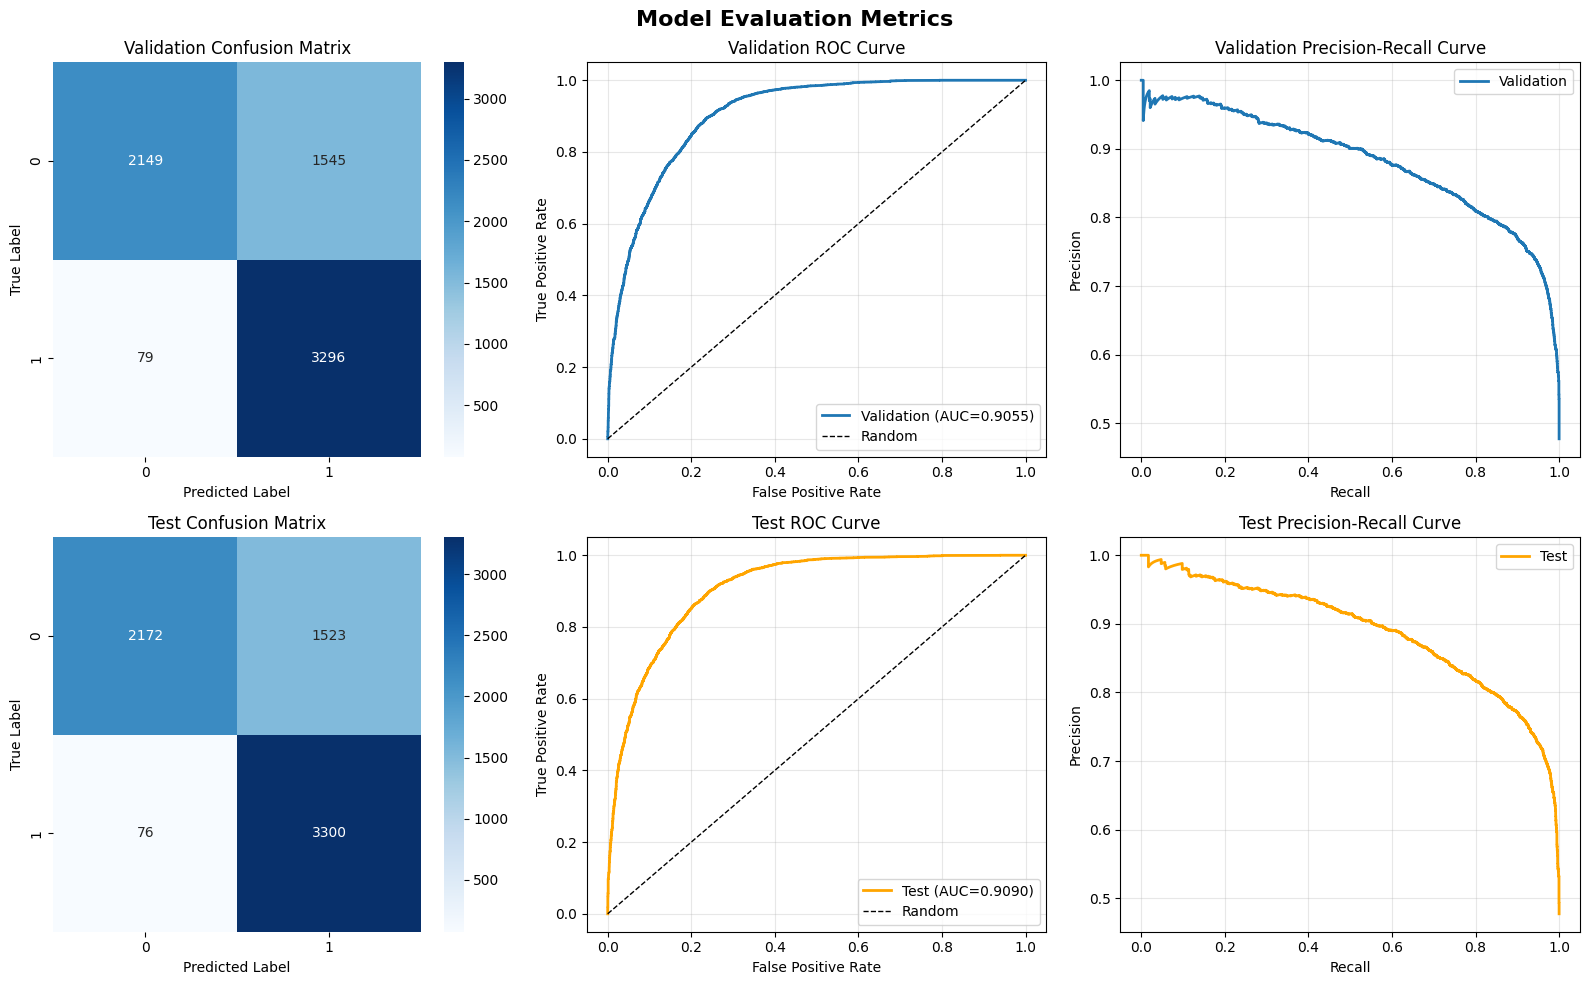


✅ Plots generated successfully!


In [7]:
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, f1_score
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
import os

# ── Update BASE_PATH to use the new merged dataset ──
# Option 1: Use the new merged dataset
BASE_PATH = "../dataset/complete_merged_dataset"

# If the merged dataset doesn't exist, use the old one
if not os.path.exists(BASE_PATH):
    BASE_PATH = "./final_dataset_A"

print(f"Using dataset from: {BASE_PATH}")

# ── Load the model from checkpoint ──
checkpoint_path = "../../backend/models/model1/vit_finetuned.pt"
if not os.path.exists(checkpoint_path):
    checkpoint_path = "../../backend/models/model1/vit_baseline_best.pt"
    
if not os.path.exists(checkpoint_path):
    checkpoint_path = "/Users/anupdangi/Desktop/AnupAI/projects/Internship_project/deepfake_image_detection/backend/models/model1/vit_finetuned.pt"

print(f"Loading model from: {checkpoint_path}")
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
print("✅ Model checkpoint loaded")

# ── Setup data loaders ──
val_ds = datasets.ImageFolder(
    os.path.join(BASE_PATH, "val"),
    transform=transform
)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)

# Define test_loader - use "test" if it exists, otherwise use "cross_gen_test"
test_path = os.path.join(BASE_PATH, "test")
if not os.path.exists(test_path):
    test_path = os.path.join(BASE_PATH, "cross_gen_test")

test_ds = datasets.ImageFolder(test_path, transform=transform)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

print(f"✅ Validation set: {len(val_ds)} images")
print(f"✅ Test set: {len(test_ds)} images")

# ── Compute predictions and probabilities ──
def get_predictions(loader, name):
    """Get predictions, probabilities, and labels from the model"""
    model.eval()
    all_preds = []
    all_probs = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs = torch.sigmoid(logits).float().cpu().numpy()
            preds = (probs > 0.5).astype(int)
            
            all_preds.extend(preds)
            all_probs.extend(probs)
            all_labels.extend(labels.numpy())
    
    return np.array(all_preds).flatten(), np.array(all_probs).flatten(), np.array(all_labels)

# Get predictions for both sets
val_preds, val_probs, val_labels = get_predictions(val_loader, "Validation")
test_preds, test_probs, test_labels = get_predictions(test_loader, "Test")

print("\n" + "="*60)
print("CONFUSION MATRICES")
print("="*60)

# Compute and print confusion matrices
val_cm = confusion_matrix(val_labels, val_preds)
test_cm = confusion_matrix(test_labels, test_preds)

print("\n📊 VALIDATION SET Confusion Matrix:")
print(val_cm)
print(f"   Format: [[TN, FP], [FN, TP]]")
print(f"   Accuracy: {(val_preds == val_labels).mean():.4f}")
print(f"   F1 Score: {f1_score(val_labels, val_preds):.4f}")

print("\n📊 TEST SET Confusion Matrix:")
print(test_cm)
print(f"   Format: [[TN, FP], [FN, TP]]")
print(f"   Accuracy: {(test_preds == test_labels).mean():.4f}")
print(f"   F1 Score: {f1_score(test_labels, test_preds):.4f}")

# ── Create visualizations ──
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Model Evaluation Metrics", fontsize=16, fontweight='bold')

# 1. Confusion Matrices - Heatmaps
sns.heatmap(val_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], cbar=True)
axes[0, 0].set_title("Validation Confusion Matrix")
axes[0, 0].set_ylabel("True Label")
axes[0, 0].set_xlabel("Predicted Label")

sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0], cbar=True)
axes[1, 0].set_title("Test Confusion Matrix")
axes[1, 0].set_ylabel("True Label")
axes[1, 0].set_xlabel("Predicted Label")

# 2. ROC Curves
val_fpr, val_tpr, _ = roc_curve(val_labels, val_probs)
val_auc = auc(val_fpr, val_tpr)

test_fpr, test_tpr, _ = roc_curve(test_labels, test_probs)
test_auc = auc(test_fpr, test_tpr)

axes[0, 1].plot(val_fpr, val_tpr, label=f'Validation (AUC={val_auc:.4f})', linewidth=2)
axes[0, 1].plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].set_title("Validation ROC Curve")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 1].plot(test_fpr, test_tpr, label=f'Test (AUC={test_auc:.4f})', linewidth=2, color='orange')
axes[1, 1].plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].set_title("Test ROC Curve")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# 3. Precision-Recall Curves
val_precision, val_recall, _ = precision_recall_curve(val_labels, val_probs)
test_precision, test_recall, _ = precision_recall_curve(test_labels, test_probs)

axes[0, 2].plot(val_recall, val_precision, linewidth=2, label='Validation')
axes[0, 2].set_xlabel("Recall")
axes[0, 2].set_ylabel("Precision")
axes[0, 2].set_title("Validation Precision-Recall Curve")
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

axes[1, 2].plot(test_recall, test_precision, linewidth=2, color='orange', label='Test')
axes[1, 2].set_xlabel("Recall")
axes[1, 2].set_ylabel("Precision")
axes[1, 2].set_title("Test Precision-Recall Curve")
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Plots generated successfully!")